CONSOLIDADO DEL EJERCICIO PREVIO

1-Carga los datos:

Carga la tabla consolidada de datos que se realizó en el avance de proyecto con empresa aliada anterior así como también los datos de alguna otra tabla que necesites usar para el EDA o la visualización y no fueron posibles consolidar en un solo archivo.

In [3]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
os.chdir("/Users/ender/OneDrive/Documentos/Desktop/MEPI  2026/")

os.chdir("/Users/ender/Downloads/ANALISTA DE DATOS/")
df1= pd.read_csv ('dataset_consolidado_final.csv')
df1.head()
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [4]:
os.chdir("/Users/ender/Downloads/ANALISTA DE DATOS/")
df2= pd.read_csv ('dataset_consolidado_final-2.csv')
df2.head()

,ï»¿CATEGORY,ATTR1,ATTR2,ATTR3,FORMAT,SEGMENT
0,1,Cloro,Cloro,Bambino,Liquido,Bleach
1,1,Cloro,Cloro,Germicida,Liquido,Bleach
2,1,Cloro,Cloro,Mascotas,Liquido,Bleach
3,1,Cloro,Cloro,Multiusos,Gel,Bleach
4,1,Cloro,Cloro,Multiusos,Liquido,Bleach


In [ ]:
df1.info()
df2.info()

In [5]:
df1.columns = df1.columns.str.replace('ï»¿', '').str.strip()
df2.columns = df2.columns.str.replace('ï»¿', '').str.strip()

In [6]:
df1 = df1.dropna(subset=['CATEGORY'])
df2 = df2.dropna(subset=['CATEGORY'])

df1['CATEGORY'] = df1['CATEGORY'].astype(int)
df2['CATEGORY'] = df2['CATEGORY'].astype(int)

df = pd.merge(df1, df2, on='CATEGORY', how='left')

In [7]:
df1['CATEGORY'] = df1['CATEGORY'].astype(int)
df2['CATEGORY'] = df2['CATEGORY'].astype(int)
df = pd.merge(df1, df2, on='CATEGORY', how='left')

In [8]:
df['WEEK_NUM'] = df['WEEK'].str.split('-').str[0].astype(int)
df['YEAR'] = df['WEEK'].str.split('-').str[1].astype(int)

df = df.sort_values(by=['YEAR', 'WEEK_NUM'])

print("Dimensiones del dataset consolidado:", df.shape)
df.head()

Dimensiones del dataset consolidado: (5978877, 22)


,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,...,ATTR1_x,ATTR2_x,ATTR3_x,ATTR1_y,ATTR2_y,ATTR3_y,FORMAT_y,SEGMENT,WEEK_NUM,YEAR
452408,01-22,7501268200001,0.003,0.027,3.0,TOTAL AUTOS AREA 1,Blanqueadora Mexicana,La Valenciana,7.501268e+12,La Valenciana Bot.Plast. 1000Ml Nal. 750126820...,...,Cloro,Cloro,No Definido,Cloro,Cloro,Bambino,Liquido,Bleach,1,22
452409,01-22,7501268200001,0.003,0.027,3.0,TOTAL AUTOS AREA 1,Blanqueadora Mexicana,La Valenciana,7.501268e+12,La Valenciana Bot.Plast. 1000Ml Nal. 750126820...,...,Cloro,Cloro,No Definido,Cloro,Cloro,Germicida,Liquido,Bleach,1,22
452410,01-22,7501268200001,0.003,0.027,3.0,TOTAL AUTOS AREA 1,Blanqueadora Mexicana,La Valenciana,7.501268e+12,La Valenciana Bot.Plast. 1000Ml Nal. 750126820...,...,Cloro,Cloro,No Definido,Cloro,Cloro,Mascotas,Liquido,Bleach,1,22
452411,01-22,7501268200001,0.003,0.027,3.0,TOTAL AUTOS AREA 1,Blanqueadora Mexicana,La Valenciana,7.501268e+12,La Valenciana Bot.Plast. 1000Ml Nal. 750126820...,...,Cloro,Cloro,No Definido,Cloro,Cloro,Multiusos,Gel,Bleach,1,22
452412,01-22,7501268200001,0.003,0.027,3.0,TOTAL AUTOS AREA 1,Blanqueadora Mexicana,La Valenciana,7.501268e+12,La Valenciana Bot.Plast. 1000Ml Nal. 750126820...,...,Cloro,Cloro,No Definido,Cloro,Cloro,Multiusos,Liquido,Bleach,1,22


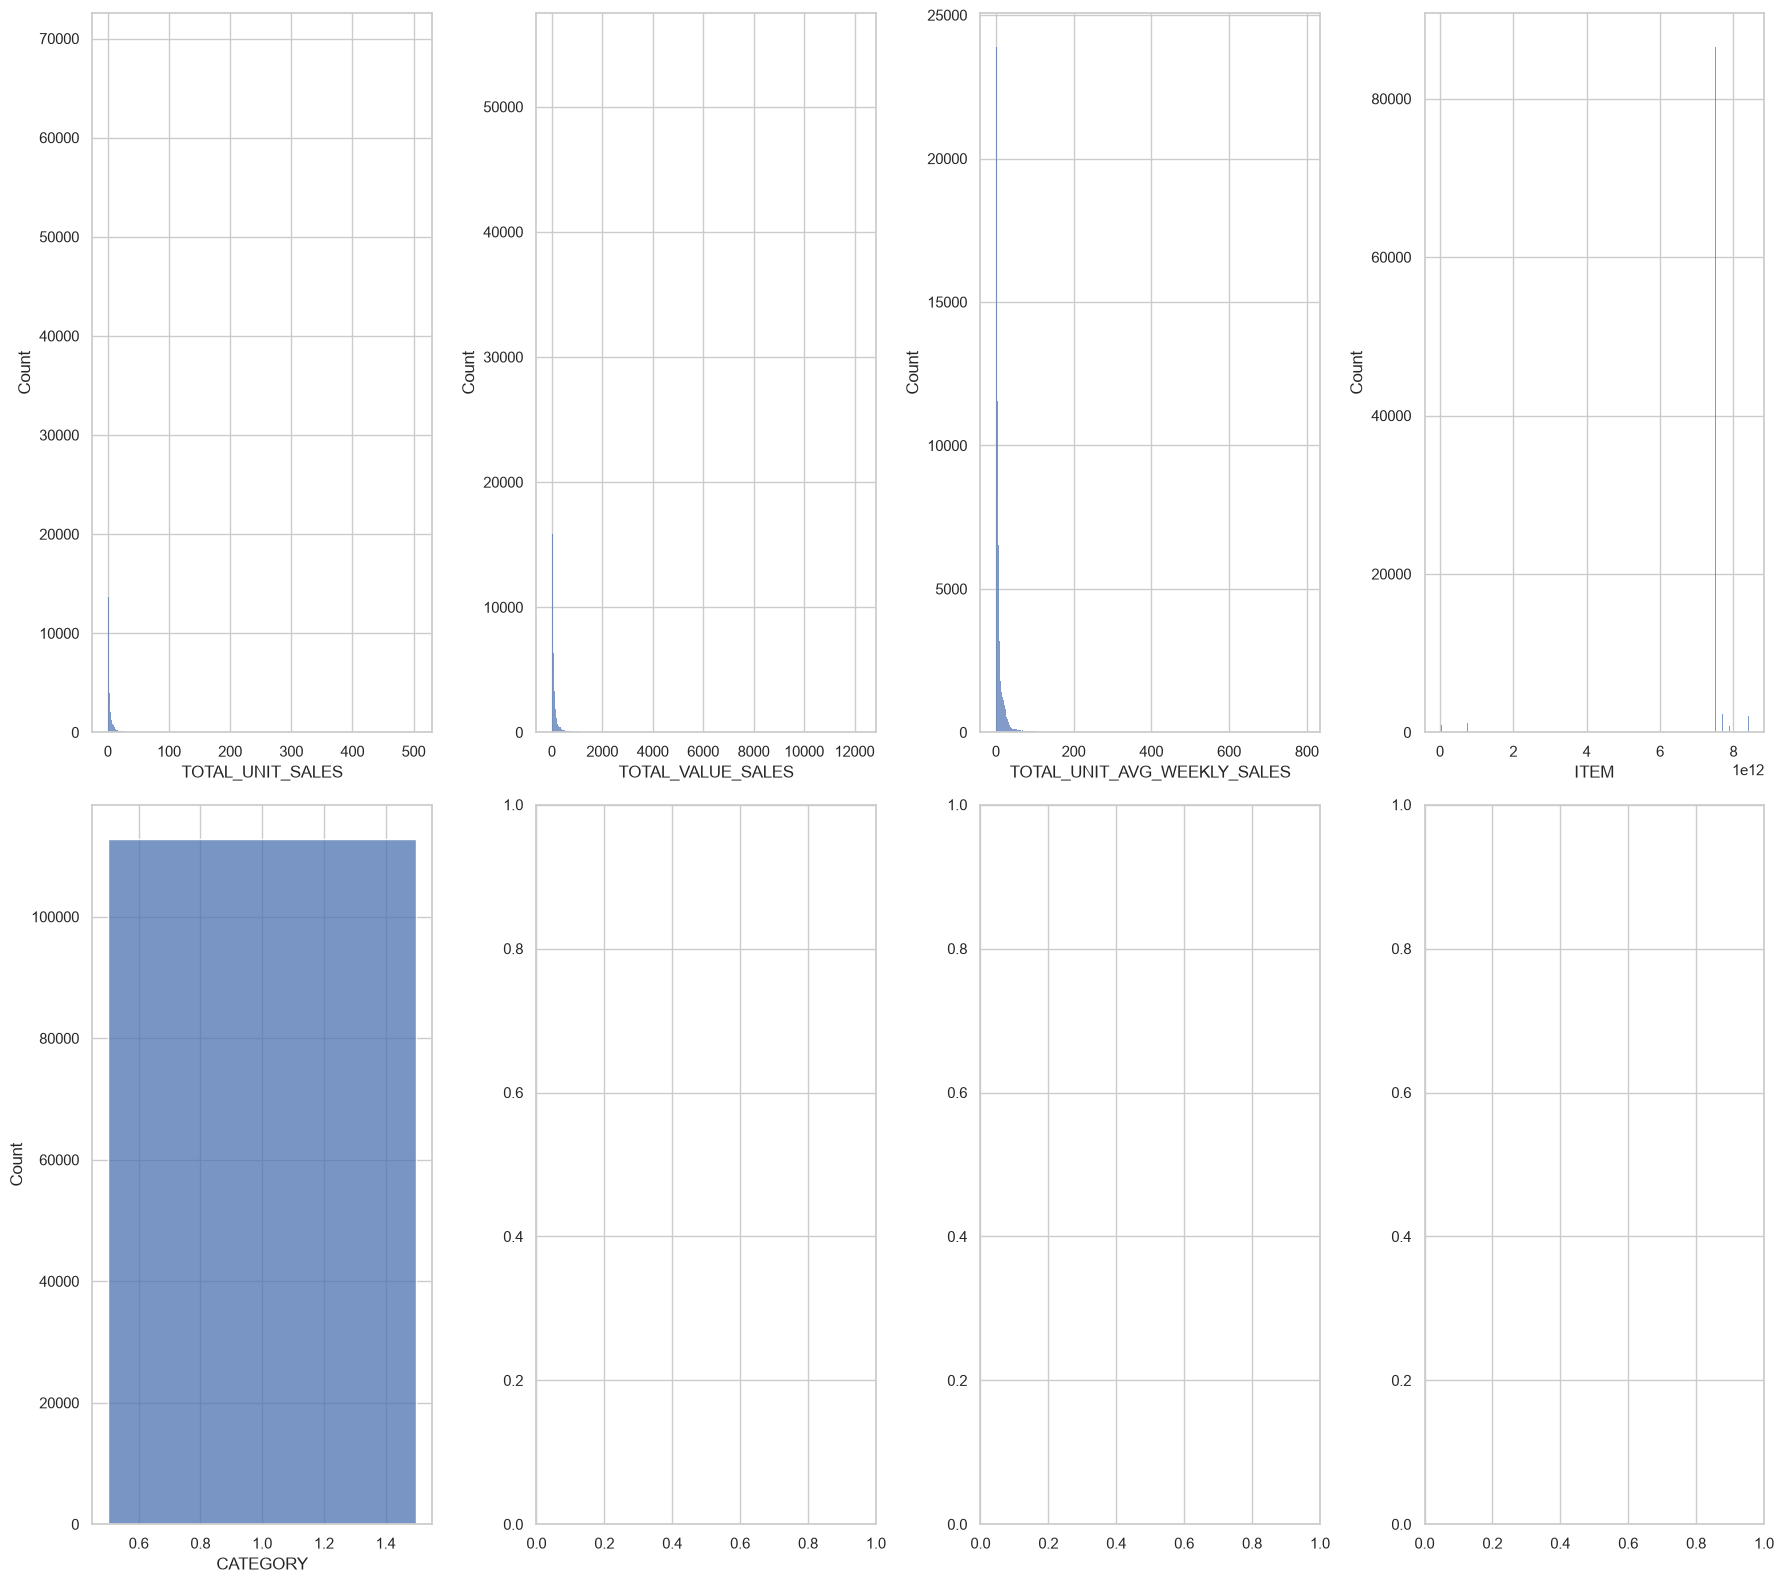

In [21]:
# Select only numeric columns
cols_num = df1.select_dtypes(include='number').columns

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 16))

for i, column in enumerate(cols_num):
    sns.histplot(
        df1[column],
        ax=axes[i // 4, i % 4],
        kde=False
    )

plt.tight_layout()
plt.show()

2-Identificar las variables clave para el análisis:

Determina qué variables son más relevantes para responder a las preguntas de negocio. 

Las variables más relevantes son:
oBJETIVO: `TOTAL_VALUE_SALES` (Valor de ventas) y `TOTAL_UNIT_SALES` (Volumen).
TEMPORALES: `WEEK`, `YEAR` (Para tendencias).
CATEGORÍA: `REGION` (Geografía), `CATEGORY` / `SEGMENT` (Rubro de negocio), `BRAND` (Marca).
La correlación entre `TOTAL_UNIT_SALES` y `TOTAL_VALUE_SALES` 

3-Visualizar la distribución de ventas:

Crea gráficos de distribución (histogramas o boxplots) para visualizar la distribución de ventas por diferentes categorías. Esto ayudará a identificar patrones de ventas y posibles outliers.

C:\Users\ender\AppData\Local\Temp\ipykernel_23124\2003428940.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='CATEGORY', y='TOTAL_VALUE_SALES', ax=axes[1], palette='Set2')


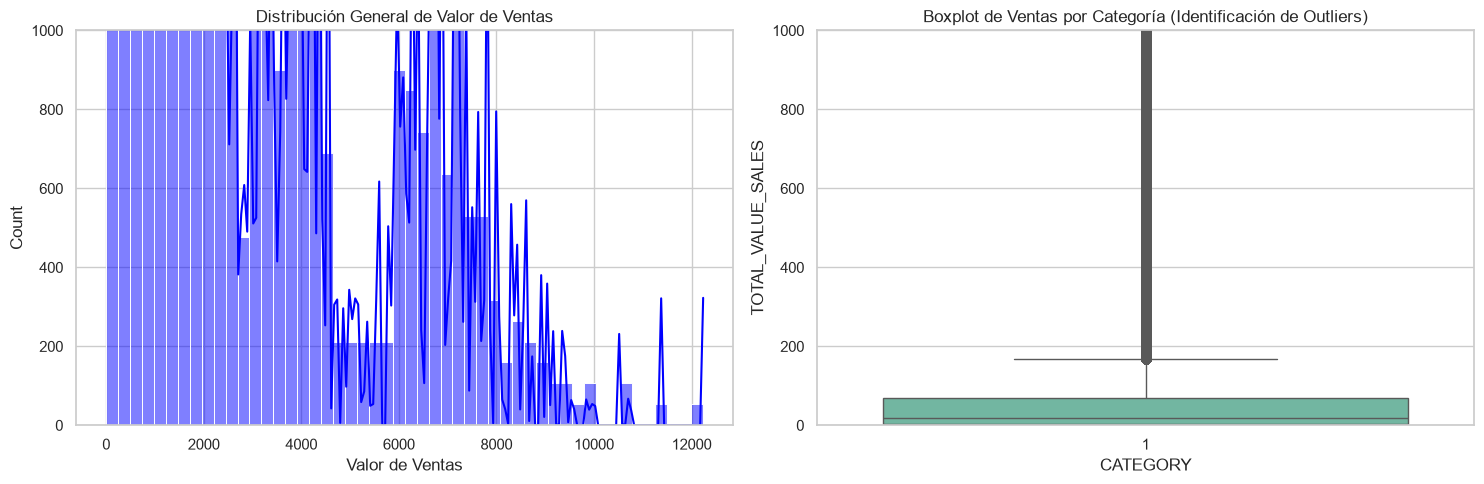

In [16]:
#Histograma de la distribución general de ventas
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df['TOTAL_VALUE_SALES'], bins=50, kde=True, ax=axes[0], color='blue')
axes[0].set_title("Distribución General de Valor de Ventas")
axes[0].set_xlabel("Valor de Ventas")
axes[0].set_ylim(0, 1000) 
# Boxplot para identificar Outliers por Categoría
sns.boxplot(data=df, x='CATEGORY', y='TOTAL_VALUE_SALES', ax=axes[1], palette='Set2')
axes[1].set_title("Boxplot de Ventas por Categoría (Identificación de Outliers)")
axes[1].set_ylim(0, 1000) 
plt.tight_layout()
plt.show()

In [17]:
cols_num1 = ['WEEK', 'ITEM_CODE', 'TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES',
       'TOTAL_UNIT_AVG_WEEKLY_SALES', 'REGION', 'ï»¿MANUFACTURER', 'BRAND',
       'ITEM', 'ITEM_DESCRIPTION', 'CATEGORY', 'FORMAT', 'ATTR1', 'ATTR2','CATEGORY', 'ATTR1', 'ATTR2', 'ATTR3', 'FORMAT', 'SEGMENT',
       'ATTR3']

In [18]:

df3=df.groupby(['BRAND','REGION'])['TOTAL_UNIT_SALES'].mean().sort_values(ascending=False).head(100)

Text(0.5, 0, 'Marca')

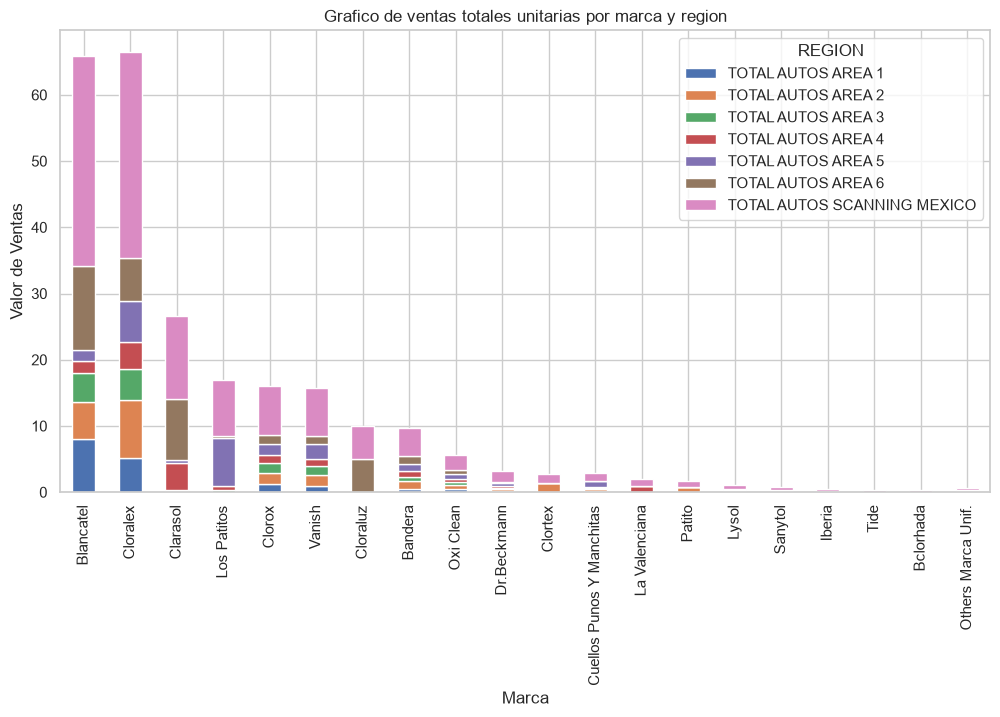

In [25]:
df3.unstack().plot.bar(stacked=True)
plt.title("Grafico de ventas totales unitarias por marca y region")
plt.ylabel("Valor de Ventas")
plt.xlabel('Marca')
 

Text(0.5, 0, 'Marca')

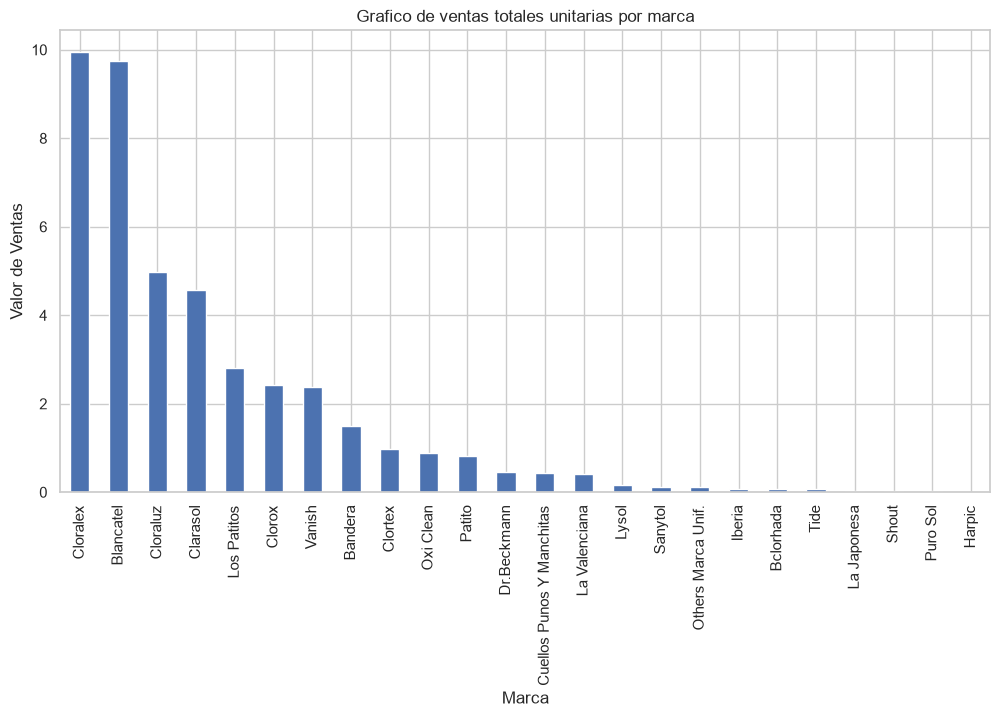

In [42]:
df4=df.groupby(['BRAND'])['TOTAL_UNIT_SALES'].mean().sort_values(ascending=False).head(100).plot.bar(stacked=True)
plt.title("Grafico de ventas totales unitarias por marca")
plt.ylabel("Valor de Ventas")
plt.xlabel('Marca')

Text(0.5, 0, 'MANUFACTURER')

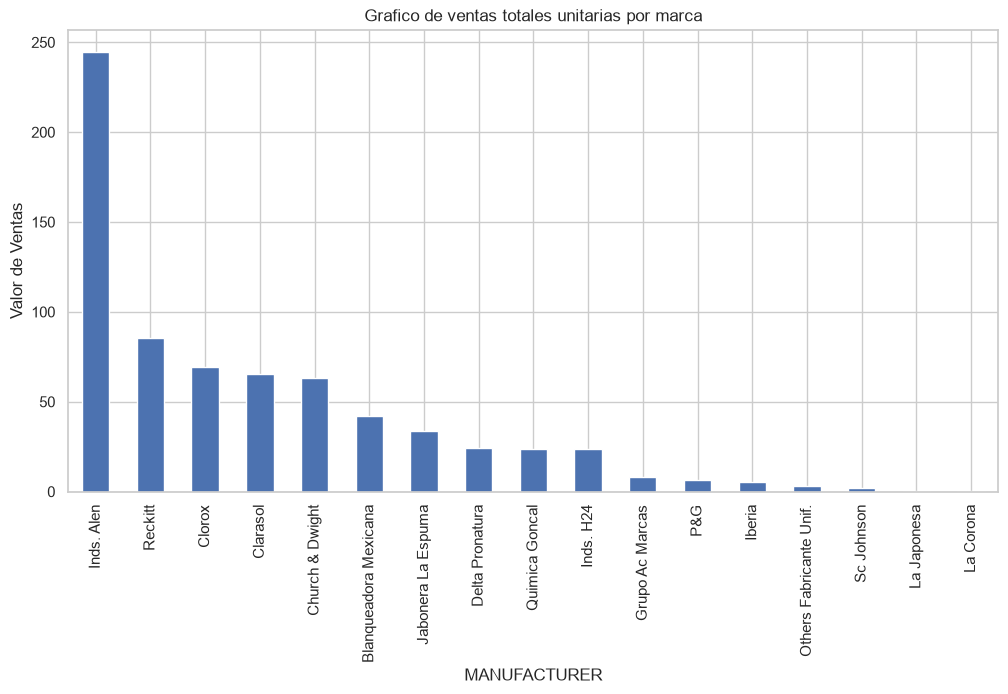

In [47]:
df5=df.groupby(['MANUFACTURER'])['TOTAL_VALUE_SALES'].mean().sort_values(ascending=False).head(100).plot.bar(stacked=True)
plt.title("Grafico de ventas totales unitarias por marca")
plt.ylabel("Valor de Ventas")
plt.xlabel('MANUFACTURER')

4-Analizar la tendencia de ventas en el tiempo:

Genera gráficos de líneas que muestren las tendencias de ventas a lo largo del tiempo. Filtra las ventas por diferentes productos, regiones o segmentos para analizar cómo han cambiado las ventas a lo largo del tiempo.

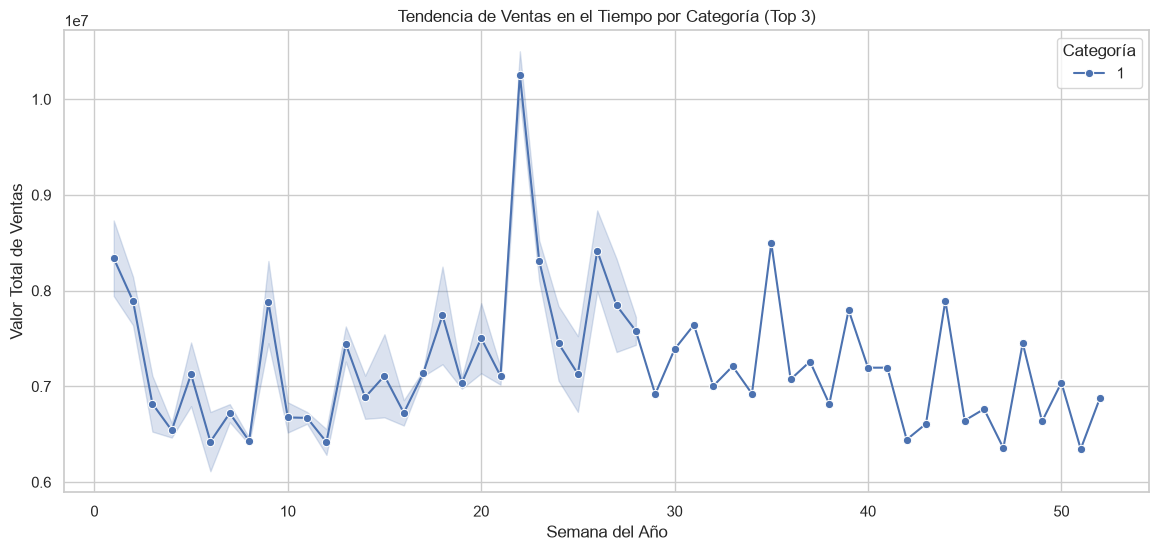

In [10]:
# Agrupamos por Semana y Categoría para ver la tendencia
time_series_data = df.groupby(['YEAR', 'WEEK_NUM', 'CATEGORY'])['TOTAL_VALUE_SALES'].sum().reset_index()

# Filtramos las 3 categorías con más ventas para que la gráfica sea legible
top_categories = df['CATEGORY'].value_counts().head(3).index
time_series_filtered = time_series_data[time_series_data['CATEGORY'].isin(top_categories)]

plt.figure(figsize=(14, 6))
sns.lineplot(data=time_series_filtered, x='WEEK_NUM', y='TOTAL_VALUE_SALES', hue='CATEGORY', marker='o')
plt.title("Tendencia de Ventas en el Tiempo por Categoría (Top 3)")
plt.xlabel("Semana del Año")
plt.ylabel("Valor Total de Ventas")
plt.legend(title='Categoría')
plt.show()

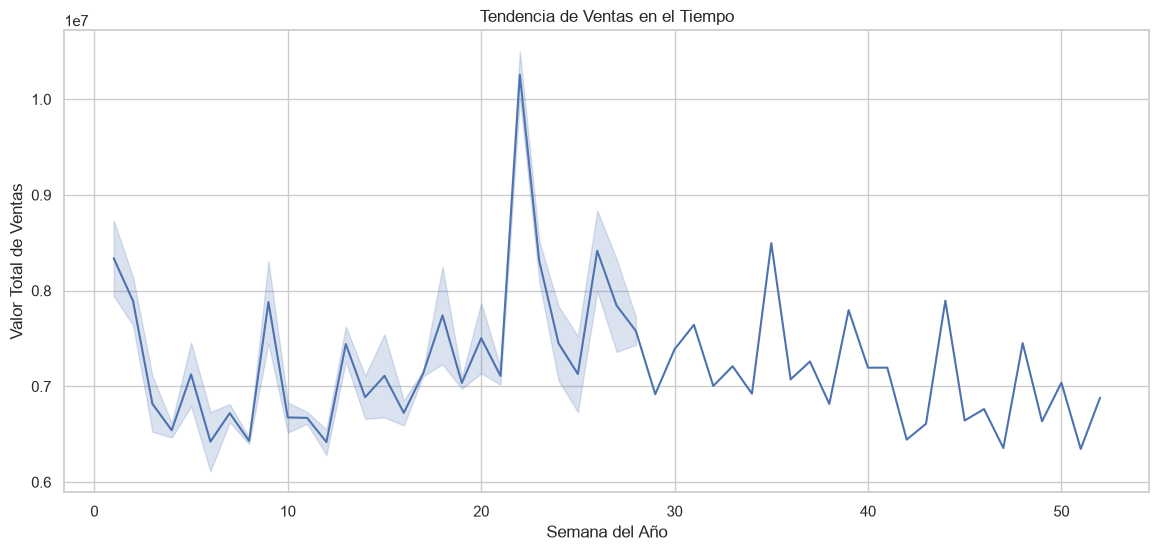

In [50]:
# Agrupamos por Semana y Categoría para ver la tendencia
time_series_data = df.groupby(['YEAR', 'WEEK_NUM'])['TOTAL_VALUE_SALES'].sum().reset_index()

plt.figure(figsize=(14, 6))
sns.lineplot(data=time_series_data, x='WEEK_NUM', y='TOTAL_VALUE_SALES')
plt.title("Tendencia de Ventas en el Tiempo")
plt.xlabel("Semana del Año")
plt.ylabel("Valor Total de Ventas")
plt.show()

5-Explorar la relación entre diferentes variables:

Utiliza gráficos de dispersión (scatter plots) para investigar relaciones entre variables clave. Esto puede ayudar a identificar correlaciones significativas entre diferentes variables.

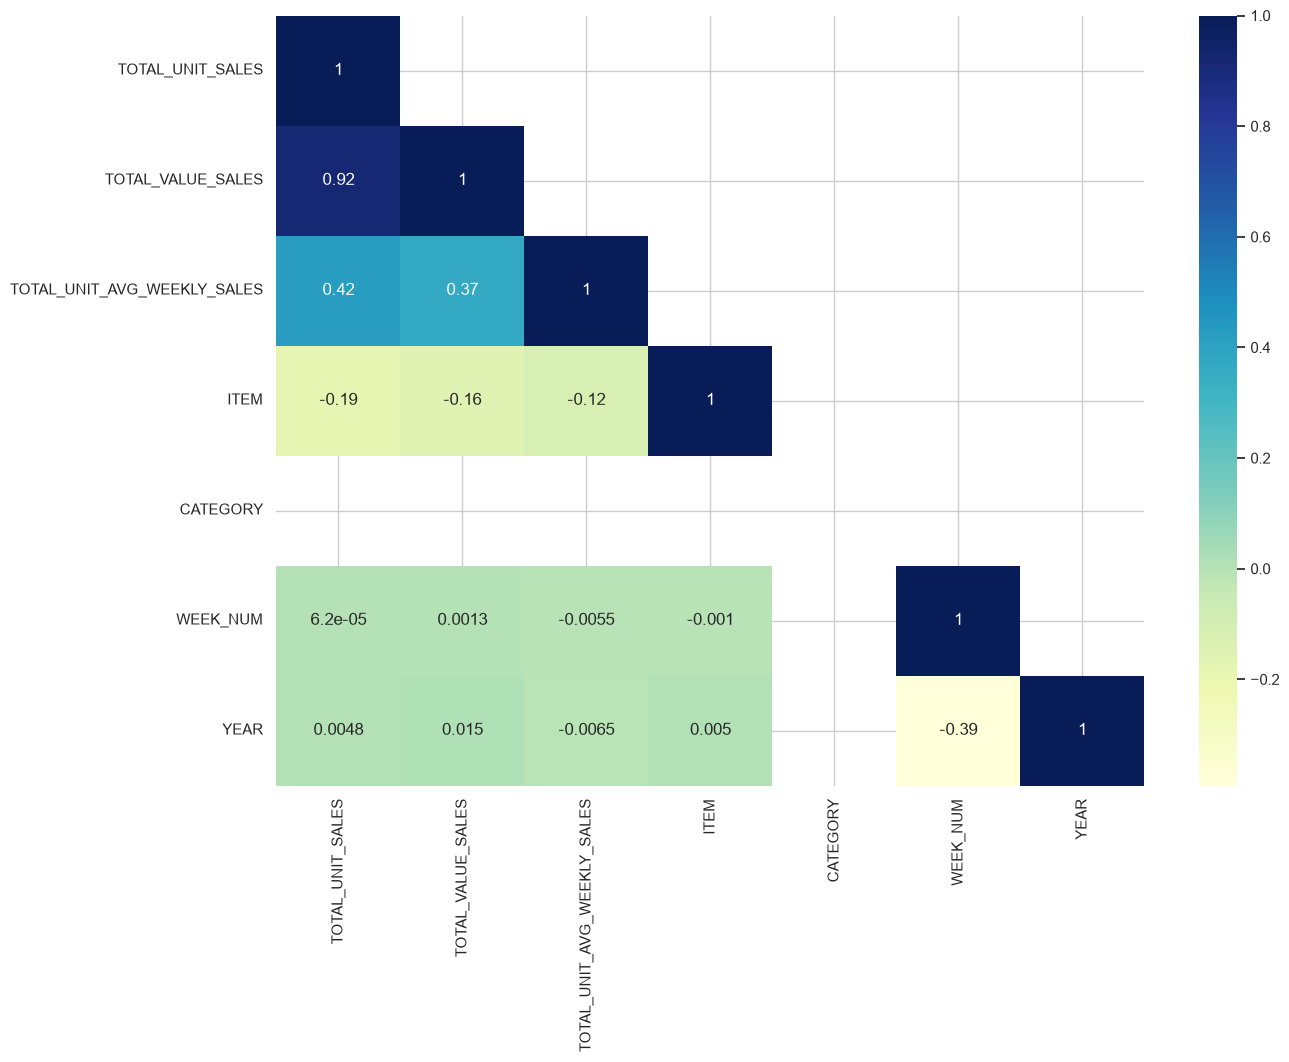

In [15]:
#CORRELACION
plt.figure(figsize=(14,10))
corr_df = corr = df.corr(method= 'pearson',numeric_only=True)
df_lt=corr_df.where(np.tril(np.ones(corr_df.shape)).astype(bool))
hmap=sns.heatmap(df_lt, cmap ='YlGnBu', annot=True)

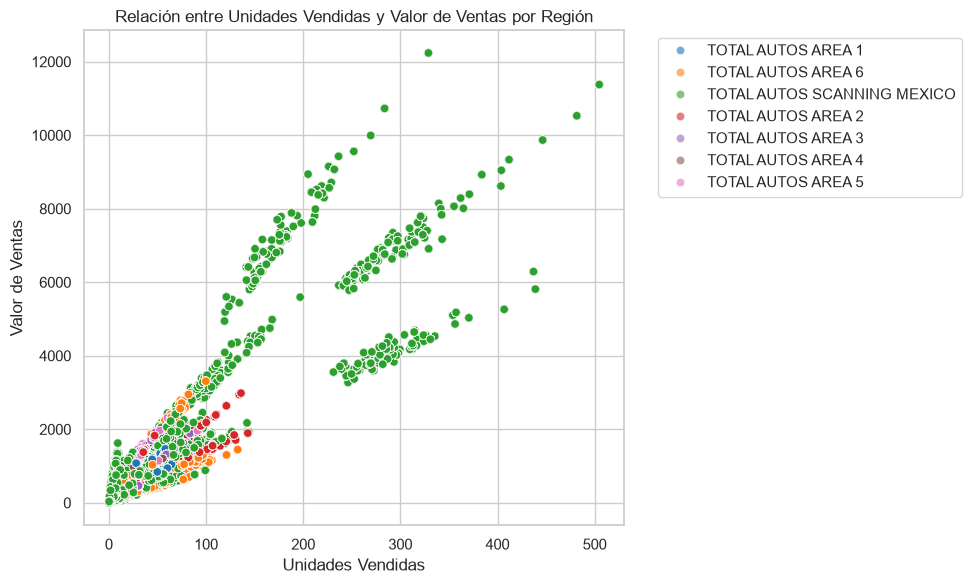

In [11]:
# Scatter Plot: Relación entre Volumen (Unidades) y Valor ($)
plt.figure(figsize=(10, 6))
# Usamos alpha para ver la densidad de los puntos
sns.scatterplot(data=df, x='TOTAL_UNIT_SALES', y='TOTAL_VALUE_SALES', hue='REGION', alpha=0.6, palette='tab10')
plt.title("Relación entre Unidades Vendidas y Valor de Ventas por Región")
plt.xlabel("Unidades Vendidas")
plt.ylabel("Valor de Ventas")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

6-Visualizar la distribución geográfica de las ventas:

Si es posible, utiliza mapas o gráficos de barras apiladas para visualizar las ventas por región. Esto puede ayudar a identificar qué regiones tienen el mayor o menor rendimiento.

<Figure size 1400x700 with 0 Axes>

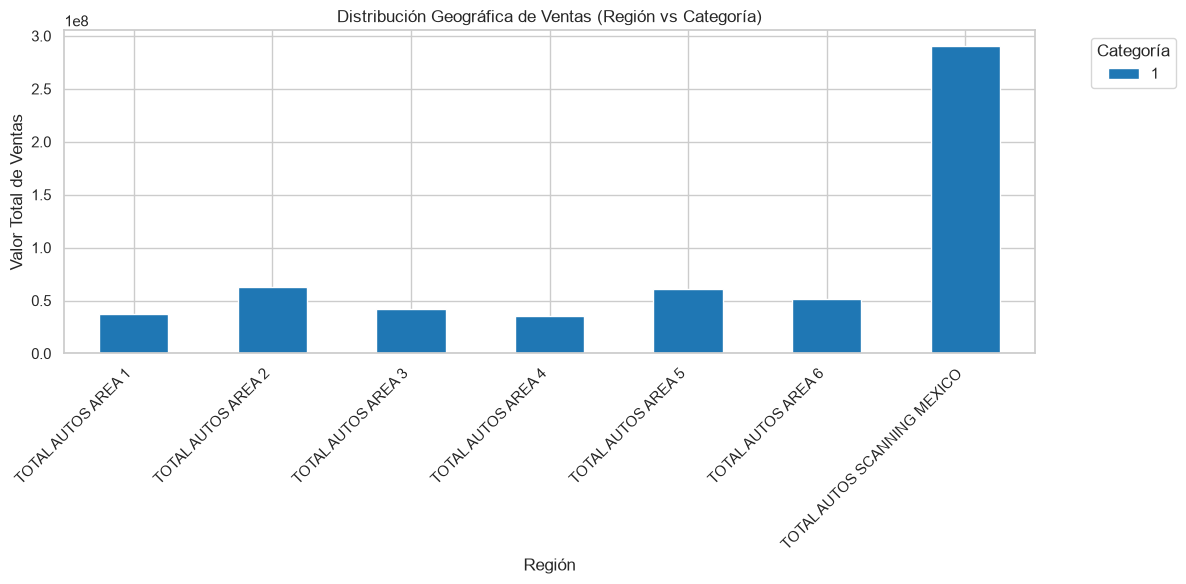

In [12]:
# Gráfica de Barras Apiladas: Ventas por Región desglosadas por Categoría
pivot_geo = df.pivot_table(values='TOTAL_VALUE_SALES', index='REGION', columns='CATEGORY', aggfunc='sum')

plt.figure(figsize=(14, 7))
pivot_geo.plot(kind='bar', stacked=True, colormap='tab20')
plt.title("Distribución Geográfica de Ventas (Región vs Categoría)")
plt.xlabel("Región")
plt.ylabel("Valor Total de Ventas")
plt.xticks(rotation=45, ha='right')
plt.legend(title='Categoría', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

7-Identificar posibles outliers y anomalías:

Utiliza gráficos de caja (boxplots) para identificar posibles outliers en los datos de ventas por producto, categoría o región. Identificar outliers puede ayudar a entender mejor los patrones inusuales o anómalos en los datos.

C:\Users\ender\AppData\Local\Temp\ipykernel_23124\3581446514.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_brands, x='BRAND', y='TOTAL_VALUE_SALES', palette='viridis')


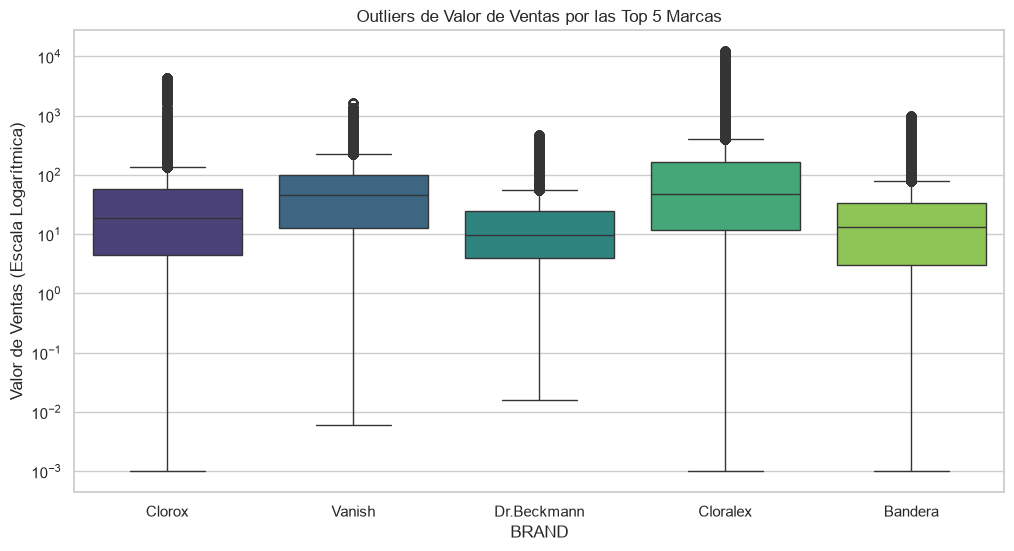

In [13]:
# Boxplot de Ventas por las Top 5 Marcas
top_brands = df['BRAND'].value_counts().head(5).index
df_brands = df[df['BRAND'].isin(top_brands)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_brands, x='BRAND', y='TOTAL_VALUE_SALES', palette='viridis')
plt.title("Outliers de Valor de Ventas por las Top 5 Marcas")
plt.yscale('log') # Escala logarítmica para poder ver las cajas a pesar de los outliers extremos
plt.ylabel("Valor de Ventas (Escala Logarítmica)")
plt.show()